# ML 05 — Ridge regression: regularized linear baseline

Ridge regression is a transparent baseline for the scalar target. It minimizes squared prediction error with an L2 coefficient penalty. Numeric features are imputed and standardized inside each training fold; categorical features are imputed and one-hot encoded inside the same pipeline. The main score is out-of-fold performance under family-held-out 5-fold validation, compared with a mean predictor.

In [1]:
from pathlib import Path
import os

# Works whether Jupyter starts in the repository root or this notebook's folder.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "data" / "raw").exists() and (p / "Machine Learning Pipeline").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the repository root. Open this notebook from inside the T006 project folder.")
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

processed_path = DATA_PROCESSED / "feature_engineered_dataset.csv"
if not processed_path.exists():
    raise FileNotFoundError("Run ML_01, then ML_03 first; ML_03 builds the engineered modelling dataset from raw data.")
df = pd.read_csv(processed_path)
TARGET = "target_U_canopy_mean_m_s"
NUMERIC_FEATURES = ["plan_area_density", "plan_area_density_sq", "height_std_m", "height_max_m", "height_min_m", "height_range_m", "height_skew", "frac_taller_than_mean", "wind_direction_sin", "wind_direction_cos", "height_coefficient_variation"]
CATEGORICAL_FEATURES = ["configuration", "horizontal_configuration", "density_class"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
BASELINE_NUMERIC = ["plan_area_density", "height_std_m", "height_max_m", "building_count", "wind_direction_sin", "wind_direction_cos"]
BASELINE_FEATURES = BASELINE_NUMERIC + CATEGORICAL_FEATURES
print("Dataset shape:", df.shape)
print("Target:", TARGET)

Dataset shape: (224, 22)
Target: target_U_canopy_mean_m_s


## 1. Define the Ridge pipeline

Ridge's L2 penalty reduces coefficient magnitude and can stabilize a linear model when geometry descriptors are correlated. Standardization is particularly important because the penalty otherwise acts differently on differently scaled variables. The chosen `alpha=1.0` is a documented baseline setting, not a claimed globally optimal hyperparameter.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC_FEATURES),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_FEATURES),
])
model = Pipeline([("preprocess", preprocessor), ("ridge", Ridge(alpha=1.0))])
X = df[FEATURES]
y = df[TARGET]
groups = df["family_id"]
cv = GroupKFold(n_splits=5)

## 2. Train and predict each held-out fold

In [4]:
prediction_rows = []
fold_rows = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
    fold_model = Pipeline([("preprocess", preprocessor), ("ridge", Ridge(alpha=1.0))])
    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])
    predictions = fold_model.predict(X.iloc[test_idx])
    observed = y.iloc[test_idx].to_numpy()
    fold_rows.append({
        "fold": fold, "n_test_cases": len(test_idx),
        "mae_m_s": mean_absolute_error(observed, predictions),
        "rmse_m_s": np.sqrt(mean_squared_error(observed, predictions)),
        "r2": r2_score(observed, predictions),
    })
    for idx, actual, pred in zip(test_idx, observed, predictions):
        prediction_rows.append({
            "fold": fold, "simulation_id": df.iloc[idx]["simulation_id"],
            "layout_id": df.iloc[idx]["layout_id"], "family_id": df.iloc[idx]["family_id"],
            "observed": float(actual), "predicted": float(pred), "model": "Ridge Regression"
        })

fold_metrics = pd.DataFrame(fold_rows)
predictions_df = pd.DataFrame(prediction_rows)
display(fold_metrics.round(4))
assert predictions_df["simulation_id"].nunique() == len(df), "Every case must be predicted exactly once."

,fold,n_test_cases,mae_m_s,rmse_m_s,r2
0,1,56,0.4441,0.6188,0.7590
1,2,42,0.3363,0.3556,0.6813
2,3,42,0.4631,0.5568,0.7671
3,4,42,0.3713,0.4763,0.4432
4,5,42,0.3729,0.4448,0.7218


## 3. Calculate pooled out-of-fold metrics

,model,n_cases,mae_m_s,rmse_m_s,r2
0,Ridge Regression,224,0.4004,0.5072,0.7401


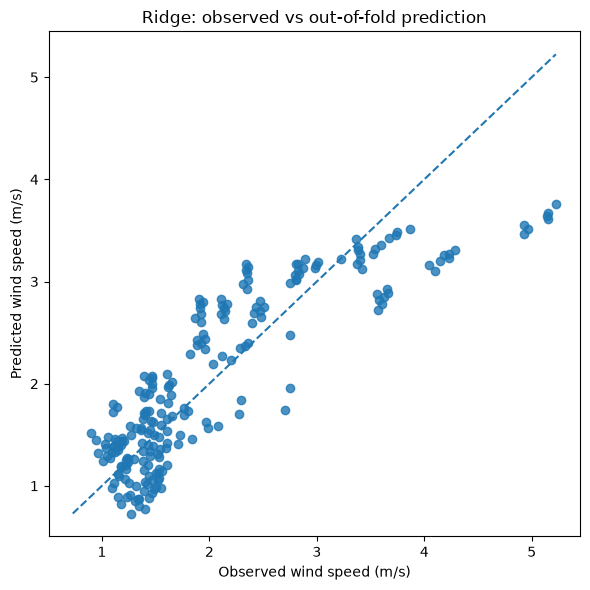

In [5]:
mae = mean_absolute_error(predictions_df.observed, predictions_df.predicted)
rmse = np.sqrt(mean_squared_error(predictions_df.observed, predictions_df.predicted))
r2 = r2_score(predictions_df.observed, predictions_df.predicted)
summary = pd.DataFrame([{"model": "Ridge Regression", "n_cases": len(predictions_df), "mae_m_s": mae, "rmse_m_s": rmse, "r2": r2}])
display(summary.round(4))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(predictions_df.observed, predictions_df.predicted, alpha=0.8)
low = min(predictions_df.observed.min(), predictions_df.predicted.min())
high = max(predictions_df.observed.max(), predictions_df.predicted.max())
ax.plot([low, high], [low, high], linestyle="--")
ax.set(xlabel="Observed wind speed (m/s)", ylabel="Predicted wind speed (m/s)", title="Ridge: observed vs out-of-fold prediction")
plt.tight_layout()
plt.show()

## 4. Regularization sensitivity (not a test-set tuning step)

The next experiment compares a small prespecified set of alpha values under the same grouped folds. This is a sensitivity analysis to show how the penalty affects out-of-fold error; it is not a nested hyperparameter optimization and should not be presented as one.

,alpha,mae_m_s,rmse_m_s,r2
0,0.01,0.4020,0.4789,0.7682
1,0.10,0.4006,0.4800,0.7671
2,1.00,0.4004,0.5072,0.7401
3,10.00,0.4268,0.5791,0.6611
4,100.00,0.4730,0.6654,0.5525


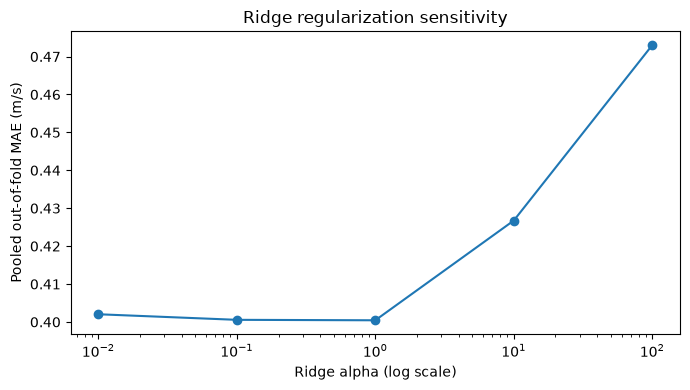

Interpretation: stronger alpha means stronger coefficient shrinkage. Do not choose an alpha based on a repeatedly inspected final test set; use nested grouped CV for formal tuning.


In [6]:
alpha_rows = []
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    alpha_predictions = []
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
        model = Pipeline([("preprocess", preprocessor), ("ridge", Ridge(alpha=alpha))])
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        alpha_predictions.extend(zip(y.iloc[test_idx].to_numpy(), pred))
    observed = np.array([x[0] for x in alpha_predictions]); predicted = np.array([x[1] for x in alpha_predictions])
    alpha_rows.append({"alpha": alpha, "mae_m_s": mean_absolute_error(observed, predicted), "rmse_m_s": np.sqrt(mean_squared_error(observed, predicted)), "r2": r2_score(observed, predicted)})
alpha_sensitivity = pd.DataFrame(alpha_rows)
display(alpha_sensitivity.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alpha_sensitivity.alpha, alpha_sensitivity.mae_m_s, marker="o")
ax.set_xscale("log"); ax.set(title="Ridge regularization sensitivity", xlabel="Ridge alpha (log scale)", ylabel="Pooled out-of-fold MAE (m/s)")
plt.tight_layout(); plt.show()
print("Interpretation: stronger alpha means stronger coefficient shrinkage. Do not choose an alpha based on a repeatedly inspected final test set; use nested grouped CV for formal tuning.")

## 4. Save results generated in this run

In [7]:
fold_metrics.to_csv(RESULTS / "ridge_fold_metrics.csv", index=False)
predictions_df.to_csv(RESULTS / "ridge_oof_predictions.csv", index=False)
summary.to_csv(RESULTS / "ridge_model_metrics.csv", index=False)
print("Created fresh outputs:")
for path in [RESULTS / "ridge_fold_metrics.csv", RESULTS / "ridge_oof_predictions.csv", RESULTS / "ridge_model_metrics.csv"]:
    print(" -", path)

Created fresh outputs:
 - /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/results/ridge_fold_metrics.csv
 - /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/results/ridge_oof_predictions.csv
 - /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/results/ridge_model_metrics.csv
